Jumlah baris awal: 1338
Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

--- Parameter Historis Klaim (charges) ---
Mean (μ)     : 13,270.42
Std Dev (σ)  : 12,110.01


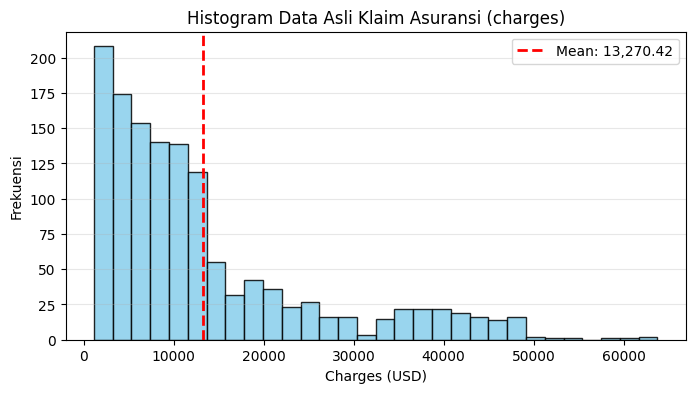

In [2]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 0. Ekstrak archive (2).zip jika insurance.csv belum ada
with zipfile.ZipFile("archive (2).zip", "r") as zip_ref:
  zip_ref.extractall(".")

# 1. Load & Cleaning Dataset
df = pd.read_csv("insurance.csv")
print("Jumlah baris awal:", len(df))
print("Missing values:\n", df.isnull().sum())

# Hapus baris kosong jika ada pada kolom 'charges'
df = df.dropna(subset=["charges"]).copy()

# 2. Ekstraksi Parameter dari kolom 'charges' (NIM berakhiran 5 -> Estimasi Risiko Klaim Asuransi)
charges = df["charges"]
mean_charge = charges.mean()
std_charge = charges.std()

print("\n--- Parameter Historis Klaim (charges) ---")
print(f"Mean (μ)     : {mean_charge:,.2f}")
print(f"Std Dev (σ)  : {std_charge:,.2f}")

# 3. Visualisasi Histogram Data Asli
plt.figure(figsize=(8, 4))
plt.hist(charges, bins=30, color="skyblue", edgecolor="black", alpha=0.85)
plt.axvline(
    mean_charge,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_charge:,.2f}",
)
plt.title("Histogram Data Asli Klaim Asuransi (charges)")
plt.xlabel("Charges (USD)")
plt.ylabel("Frekuensi")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

Rata-rata Estimasi Total Klaim (100 pasien): 1,411,936.29
Batas Anggaran (Threshold)                 : 1,400,000.00
Skenario Melebihi Anggaran                 : 5389 / 10000
Probabilitas Melebihi Anggaran P(Event)    : 53.89%


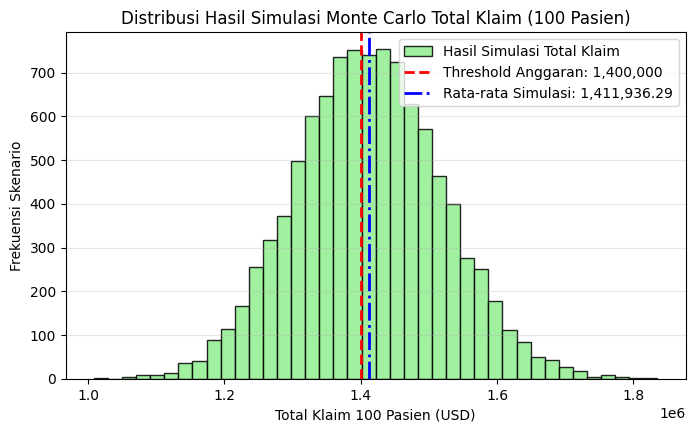

In [3]:
# 4. Simulasi Monte Carlo (Minimal 5.000 skenario)
np.random.seed(301240025)  # Seed sesuai NIM

num_simulations = 10000     # Jumlah skenario (>= 5.000)[cite: 13]
num_patients = 100          # 100 pasien baru sesuai pertanyaan simulasi[cite: 12]
budget_threshold = 1400000  # Contoh batas anggaran klaim: $1,400,000 (bisa disesuaikan)

total_claims = []
for _ in range(num_simulations):
    # Bangkitkan 100 nilai klaim acak dari distribusi normal (μ, σ)[cite: 13]
    sim_charges = np.random.normal(loc=mean_charge, scale=std_charge, size=num_patients)
    sim_charges = np.maximum(sim_charges, 0)  # Klaim tidak mungkin negatif
    total_claims.append(np.sum(sim_charges))

total_claims = np.array(total_claims)

# 5. Hitung Probabilitas Risiko[cite: 13]
exceed_budget = np.sum(total_claims > budget_threshold)
prob_exceed = (exceed_budget / num_simulations) * 100
mean_total_sim = np.mean(total_claims)

print(f"Rata-rata Estimasi Total Klaim (100 pasien): {mean_total_sim:,.2f}")
print(f"Batas Anggaran (Threshold)                 : {budget_threshold:,.2f}")
print(f"Skenario Melebihi Anggaran                 : {exceed_budget} / {num_simulations}")
print(f"Probabilitas Melebihi Anggaran P(Event)    : {prob_exceed:.2f}%")

# 6. Visualisasi Hasil Simulasi & Garis Batas (Threshold)[cite: 13]
plt.figure(figsize=(8, 4.5))
plt.hist(total_claims, bins=40, color='lightgreen', edgecolor='black', alpha=0.85, label="Hasil Simulasi Total Klaim")
plt.axvline(budget_threshold, color='red', linestyle='--', linewidth=2, label=f"Threshold Anggaran: {budget_threshold:,.0f}")
plt.axvline(mean_total_sim, color='blue', linestyle='-.', linewidth=2, label=f"Rata-rata Simulasi: {mean_total_sim:,.2f}")
plt.title("Distribusi Hasil Simulasi Monte Carlo Total Klaim (100 Pasien)")
plt.xlabel("Total Klaim 100 Pasien (USD)")
plt.ylabel("Frekuensi Skenario")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()